In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from scipy.io import loadmat
from pathlib import Path
from matplotlib.patches import Rectangle
import re
import os


if os.getcwd().endswith('scripts'):
    os.chdir('..')
os.getcwd()

'/Users/arthur/git/Master amu/DA3/DA3_VSDI_S1_G1_2026'

In [5]:
current_dir = Path.cwd()
folder = current_dir.parent
data_folder = folder / 'data'

In [6]:
for i in folder.iterdir():
    print(i)

/Users/arthur/git/Master amu/DA3/.DS_Store
/Users/arthur/git/Master amu/DA3/DA3_VSDI_S1_G1_2026
/Users/arthur/git/Master amu/DA3/data


In [7]:
## load the condition
## condition is the order of the finger stimulations

condition_load = np.load(data_folder / 'New_list_conditions.npy')
condition = []

for i in condition_load[0::2]:
    cond = re.split('_', str(i))[0]
    condition.append(cond[-1])

condition = np.array(condition)

In [2]:
# parameters
sig = 1 ## for the gaussian filter

In [8]:
## extract data from trials

Cortex = np.load(data_folder / 'Image_Cortex.npy')  
x = np.arange(1, 31, 1)

delta_f = []

for trial_num in x:
    stim = np.load(data_folder / f'Trial_{trial_num}_Stim.npy')
    control = np.load(data_folder / f'Trial_{trial_num}_Control.npy')

    df = (stim - control)/control
    delta_f.append(df)

delta_f = np.array(delta_f)

df_filtered = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, 0)) 
# df_test = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, sig))

In [9]:
cond1_index = np.where(condition == '1')[0]
cond2_index = np.where(condition == '2')[0]
cond3_index = np.where(condition == '3')[0]

In [10]:
cond1_ave = np.mean(df_filtered[cond1_index], axis=0)
cond2_ave = np.mean(df_filtered[cond2_index], axis=0)
cond3_ave = np.mean(df_filtered[cond3_index], axis=0)

### Extract baseline

In [11]:
baseline1 = np.mean(cond1_ave[:,:,:33], axis=2)
baseline2 = np.mean(cond2_ave[:,:,:33], axis=2)
baseline3 = np.mean(cond3_ave[:,:,:33], axis=2)

### Calculate t-test

In [95]:
from scipy.stats import ttest_1samp, ttest_ind, ttest_rel, linregress

def calc_ttest(data, start, end, alpha=0.01):
    lat = np.zeros(shape=(100,100))
    for k in range(end):
        for i in range(100):
            for j in range(100):
                stat, pvalue = ttest_ind(data[i,j,:33], data[i,j,start+k], axis=0, alternative='less')
                if pvalue < alpha:
                    if lat[i,j] == 0:
                        lat[i,j] = start+k
    return lat

In [96]:
from scipy import stats

def calc_latency(data, start, n_base=33, n_post=10, alpha=0.05):
    base = data[:, :, :n_base]
    mu = base.mean(axis=2)                      
    sd = base.std(axis=2, ddof=1)               

    post = data[:, :, start:start + n_post]     

    # Crawford-Howell t: one observation vs. a baseline sample
    t = (post - mu[:,:,None]) / (sd[:,:,None] * np.sqrt(1 + 1 / n_base))
    p = 2 * stats.t.sf(np.abs(t), df=n_base - 1)  # two-sided

    sig = p < alpha                              
    first = np.argmax(sig, axis=2)               
    lat = np.where(sig.any(axis=2), start + first, 0)
    return lat

In [ ]:
lat1 = calc_ttest(cond1_ave, 35, 10, 0.01)
lat2 = calc_ttest(cond2_ave, 35, 10, 0.01)
lat3 = calc_ttest(cond3_ave, 35, 10, 0.01)

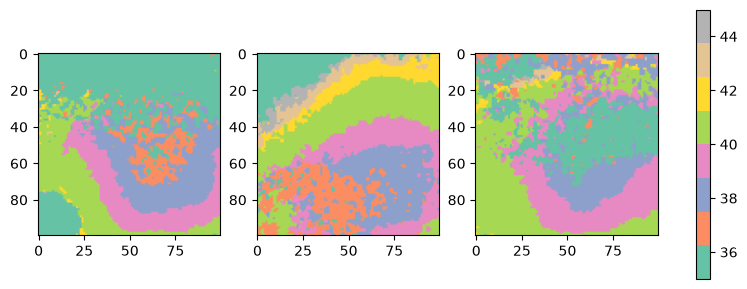

In [98]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 7))

im1 = ax1.imshow(lat1, cmap='Set2', vmin=35, vmax=45)
im2 = ax2.imshow(lat2, cmap='Set2', vmin=35, vmax=45)
im3 = ax3.imshow(lat3, cmap='Set2', vmin=35, vmax=45)

fig.colorbar(im3, ax=[ax1, ax2, ax3], shrink=0.5)

### Find latency

In [99]:
def extract_latency(data, first_lat):
    activity = np.reshape(data, (10000, 255))
    x2 = first_lat.flatten().astype(int)
    x1 = np.where(x2>0, x2-1, x2)

    y2 = activity[np.arange(10000), x2]
    y1 = activity[np.arange(10000), x1]

    m = (y2 - y1)/(x2 - x1)
    c = -m*x1 + y1

    latency = np.reshape((np.reshape(baseline1, (10000)) - c)/m, (100,100))

    return latency

In [100]:
cond1_lat = extract_latency(cond1_ave, lat1)
cond2_lat = extract_latency(cond2_ave, lat2)
cond3_lat = extract_latency(cond3_ave, lat3)

/var/folders/hj/zrv88xk141b_66z8wmnrg1d80000gp/T/ipykernel_40601/283502515.py:9: RuntimeWarning: invalid value encountered in divide
  m = (y2 - y1)/(x2 - x1)


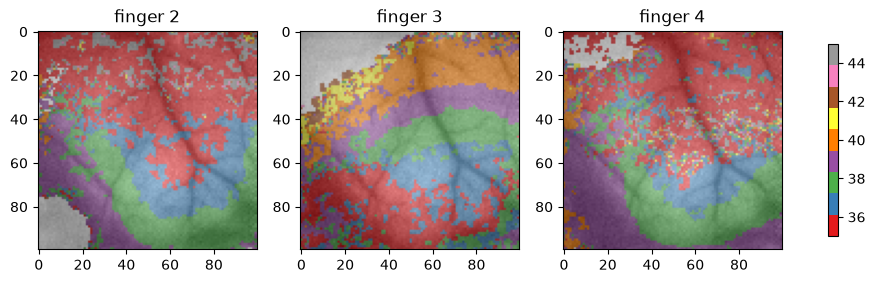

In [101]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 5))

im1 = ax1.imshow(cond1_lat, cmap='Set1', vmin=35, vmax=45)
ax1.imshow(Cortex, alpha=0.5)
ax1.set_title('finger 2')

im2 = ax2.imshow(cond2_lat, cmap='Set1', vmin=35, vmax=45)
ax2.imshow(Cortex, alpha=0.5)
ax2.set_title('finger 3')

im3 = ax3.imshow(cond3_lat, cmap='Set1', vmin=35, vmax=45)
ax3.imshow(Cortex, alpha=0.5)
ax3.set_title('finger 4')

fig.colorbar(im3, ax=[ax1, ax2, ax3], shrink=0.5)

plt.show()


### Extract the contours

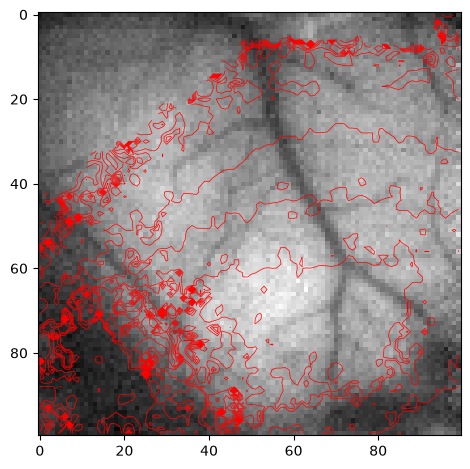

In [90]:
plt.imshow(Cortex)
plt.contour(cond2_lat, levels=50, linewidths=0.5, colors='r')
# plt.contour(cond2_lat, levels=10, linewidths=0.5, colors='g')
# plt.contour(cond3_lat, levels=10, linewidths=0.5, colors='b')

plt.tight_layout()

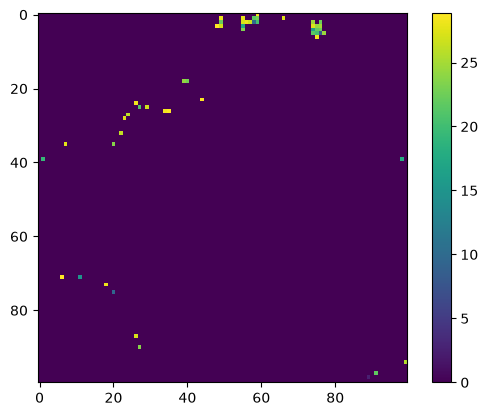

In [87]:
plt.imshow(np.where(cond1_lat<29, cond1_lat, 0))
plt.colorbar()

In [75]:
cond1_lat[cond1_lat<39]

array([33.83113294, 37.41576847, 38.8387273 , ..., 37.86189568,
       38.0196007 , 34.10771273], shape=(7800,))